In [1]:
import naive
import heaping

In [2]:
inputjets = naive.JetReader("PythiaEventsBatchTest.root",'pdEventTree')

In [3]:
heap_plant = heaping.DistHeap(inputjets, naive.d_ij_SIFT)

heap constructed, with 143 inputs, 10154 many heap entries, 10154 many pairs


In [4]:
heap_condition = True

for i in range(1, len(heap_plant.H) // 2):
    parent = heap_plant.H[i]
    c1 = heap_plant.H[2*i]
    c2 = heap_plant.H[2*i + 1]

    if c1 > c2:
        c1, c2 = c2, c1

    if parent > c1:
        heap_condition = False

    if heap_condition == False:
        print("Alert! Heap condition unsatisfied!")

if heap_condition == True:
    print("heap is all good!")

heap is all good!


In [5]:
#heap construction works
#now, obtain min. distance and min. pair

mindist, minpair = heap_plant.top()

In [6]:
minpair

[<naive.MJet at 0x7159e71e25d0>, <naive.MJet at 0x7159e71e28a0>]

In [7]:
minjet_idx_i, minjet_idx_j = heap_plant.jet_locator(minpair[0], "all"), heap_plant.jet_locator(minpair[1], "all")

In [8]:
print(minjet_idx_i, minjet_idx_j)

[1, 153, 222, 282, 612, 614, 707, 871, 1034, 1044, 1218, 1228, 1231, 1373, 1482, 1596, 1613, 1819, 2118, 2160, 2228, 2434, 2457, 2700, 2701, 2736, 2878, 2971, 2988, 3061, 3107, 3150, 3186, 3444, 3523, 3601, 3676, 3687, 3713, 3745, 3750, 3800, 3821, 3891, 3912, 3925, 3958, 3991, 4087, 4133, 4149, 4242, 4266, 4294, 4301, 4350, 4451, 4500, 4546, 4563, 4569, 4591, 4816, 4888, 4916, 4917, 4918, 4922, 4925, 4926, 5004, 5078, 5178, 5251, 5277, 5375, 5568, 5736, 5850, 6033, 6212, 6451, 6473, 6498, 6558, 6642, 6684, 6725, 6807, 6916, 6968, 7147, 7516, 7572, 7587, 7713, 8002, 8047, 8048, 8112, 8237, 8417, 8511, 8670, 8697, 8750, 8802, 8853, 8952, 9015, 9225, 9267, 9308, 9336, 9348, 9387, 9425, 9462, 9498, 9513, 9533, 9545, 9567, 9600, 9663, 9693, 9722, 9750, 9833, 9835, 9837, 9838, 9839, 9840, 9841, 9842, 9845, 9846, 9848, 9849, 9852, 9955] [1, 55, 68, 77, 101, 109, 117, 124, 139, 195, 247, 265, 281, 342, 348, 375, 389, 431, 441, 465, 471, 491, 503, 504, 518, 532, 534, 545, 572, 620, 673, 682, 7

In [9]:
before_update_H = heap_plant.H
before_update_Pairs = heap_plant.Pairs

len(before_update_Pairs)

10154

In [10]:
heap_final_jets, heap_dt = heaping.hac(inputjets, naive.d_ij_SIFT)

heap constructed, with 143 inputs, 10154 many heap entries, 10154 many pairs
next iteration; 10153 heap slots remaining...
clustering two jets...
next iteration; 10011 heap slots remaining...
clustering two jets...
next iteration; 9870 heap slots remaining...
clustering two jets...
next iteration; 9730 heap slots remaining...
clustering two jets...
next iteration; 9591 heap slots remaining...
dropping one jet...
next iteration; 9453 heap slots remaining...
clustering two jets...
next iteration; 9316 heap slots remaining...
dropping one jet...
next iteration; 9180 heap slots remaining...
dropping one jet...
next iteration; 9045 heap slots remaining...
clustering two jets...
next iteration; 8911 heap slots remaining...
clustering two jets...
next iteration; 8778 heap slots remaining...
dropping one jet...
next iteration; 8646 heap slots remaining...
clustering two jets...
next iteration; 8515 heap slots remaining...
clustering two jets...
next iteration; 8385 heap slots remaining...
drop

In [11]:
len(heap_final_jets)

14

In [12]:
naive.JetWriter('heapjets.root',heap_final_jets,'finalJets')

In [13]:
import time

naive_start = time.perf_counter()
naivehist, naivejets = naive.SIFT(inputjets)
naive_end = time.perf_counter()

naive_dt = naive_end - naive_start

In [14]:
print(f"Heaping: {heap_dt} s")
print(f"naive: {naive_dt} s")

Heaping: 0.10831263000000035 s
naive: 0.364495809999994 s


In [15]:
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
def TimingMeasurement(inputjets, ClusterFunc, *args, **kwargs):

  """
  Measures how much time it takes to cluster a set of jets.

  returns N, time_result, dt
    with N = number of initial jets clustered (including ghosts),
    time_result = average time elapsed in seconds,
    and dt = standard deviation from five trials

  """

  t_list = []

  for count in range(5):

    print(f"Trial {count} begins...")
    start = time.perf_counter()
    ClusterFunc(*args, **kwargs)
    end = time.perf_counter()

    t_list.append(end-start)
    print(f"Trial {count} complete: reading {end-start} seconds")

  dt = statistics.stdev(t_list)
  time_result = statistics.mean(t_list)



  return len(inputjets), time_result, dt

In [17]:
import statistics
#ntest, ttest, dttest = TimingMeasurement(inputjets, heaping.hac, inputjets, naive.d_ij_SIFT)

#will populate y,phi space uniformly with <gjn> x <gjn> many 'ghost jets' to pad out N value and test
#clustering speeds
gjn_nums = [i for i in range(5,11)]

#to obtain max, min rapidity values from input jet set

ymin = min([jet.y for jet in inputjets])
ymax = max([jet.y for jet in inputjets])


import numpy as np

pi = float(np.pi)


N_data = []
t_data = []
dt_data = []


#heap test
for gjn in gjn_nums:

  gjset = naive.GhostJetPopulator(list(inputjets), ymin, ymax, gjn, 0, 2*pi, gjn)

  n_result, t_result, dt_result = TimingMeasurement(gjset, heaping.hac, gjset, naive.d_ij_SIFT)
  N_data.append(n_result)
  t_data.append(t_result)
  dt_data.append(dt_result)
  

###now writing to csv:

tvNdf = pd.DataFrame({
  "t": t_data,
  "dt": dt_data,
  "N": N_data
})

###will differ when we do <Where> fixes

tvNtitle = 'timing_heap.csv'

tvNdf.to_csv(tvNtitle)


Trial 0 begins...
heap constructed, with 168 inputs, 14029 many heap entries, 14029 many pairs
next iteration; 14028 heap slots remaining...
clustering two jets...
next iteration; 13861 heap slots remaining...
clustering two jets...
next iteration; 13695 heap slots remaining...
clustering two jets...
next iteration; 13530 heap slots remaining...
clustering two jets...
next iteration; 13366 heap slots remaining...
clustering two jets...
next iteration; 13203 heap slots remaining...
dropping one jet...
next iteration; 13041 heap slots remaining...
dropping one jet...
next iteration; 12880 heap slots remaining...
dropping one jet...
next iteration; 12720 heap slots remaining...
dropping one jet...
next iteration; 12561 heap slots remaining...
dropping one jet...
next iteration; 12403 heap slots remaining...
dropping one jet...
next iteration; 12246 heap slots remaining...
dropping one jet...
next iteration; 12090 heap slots remaining...
dropping one jet...
next iteration; 11935 heap slots

In [18]:
#naive test

N_data_naive = []
t_data_naive = []
dt_data_naive = []

for gjn in gjn_nums:

  gjset = naive.GhostJetPopulator(list(inputjets), ymin, ymax, gjn, 0, 2*pi, gjn)
  print(f"N: {len(gjset)}")

  n_result, t_result, dt_result = TimingMeasurement(gjset, naive.SIFT, gjset)
  N_data_naive.append(n_result)
  t_data_naive.append(t_result)
  dt_data_naive.append(dt_result)



tvNdf_naive = pd.DataFrame({
  "t": t_data_naive,
  "dt": dt_data_naive,
  "N": N_data_naive
})

###will differ when we do <Where> fixes

tvNdf_naive.to_csv('timing_naive.csv')

N: 168
Trial 0 begins...
Trial 0 complete: reading 0.5735669140000255 seconds
Trial 1 begins...
Trial 1 complete: reading 0.5850142890000143 seconds
Trial 2 begins...
Trial 2 complete: reading 0.5528670539999894 seconds
Trial 3 begins...
Trial 3 complete: reading 0.5551907860000256 seconds
Trial 4 begins...
Trial 4 complete: reading 0.5599618210000017 seconds
N: 179
Trial 0 begins...
Trial 0 complete: reading 0.6800407859999495 seconds
Trial 1 begins...
Trial 1 complete: reading 0.6832273650001071 seconds
Trial 2 begins...
Trial 2 complete: reading 0.672509601999991 seconds
Trial 3 begins...
Trial 3 complete: reading 0.6746442830000206 seconds
Trial 4 begins...
Trial 4 complete: reading 0.676406909000093 seconds
N: 192
Trial 0 begins...
Trial 0 complete: reading 0.838330547000055 seconds
Trial 1 begins...
Trial 1 complete: reading 0.841354143999979 seconds
Trial 2 begins...
Trial 2 complete: reading 0.8434867100000929 seconds
Trial 3 begins...
Trial 3 complete: reading 0.85461463899991

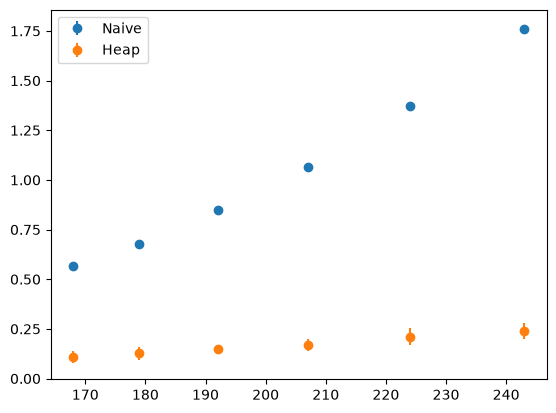

In [19]:
plt.errorbar(N_data_naive,t_data_naive,yerr=dt_data_naive,fmt="o",label="Naive")
plt.errorbar(N_data,t_data,yerr=dt_data,fmt="o",label="Heap")
plt.legend()
plt.show()